# XGBoost(eXtreme Gradient Boosting)

- 과적합 방지가 가능한 규제가 포함되어 있다.
- CART(Classification And Regression Tree)를 기반으로 하므로 분류와 회귀 둘 다 가능하다.
- 조기 종료(early stopping)을 제공한다.
- 앙상블 부스팅의 특징인 가중치 부여를 경사하강법(Gradient descent)으로 한다.

In [5]:
# xgboost 설치
# pip install xgboost

# XGBoost 버전 확인
import xgboost

print(xgboost.__version__)

3.4.1


### 위스콘신 유방암 예측

In [6]:
import pandas as pd

from sklearn import set_config
set_config(display="text")


# 유방암 관련 데이터 얻어 오기 위해 사용
from sklearn.datasets import load_breast_cancer

# 훈련용 데이터와 테스트 데이터분리를 위해 사용
from sklearn.model_selection import train_test_split



import warnings
warnings.filterwarnings('ignore')

In [7]:
# 유방암 환자 정보에 대한 데이터를 얻어오기 
dataset = load_breast_cancer()

X_features = dataset.data
y_label = dataset.target

cancer_df = pd.DataFrame(data=X_features, columns=dataset.feature_names)
cancer_df['target'] = y_label
cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [8]:
# malignant -> 0 악성종양 암!!, benign -> 1 양성 암이 아님!!!  

print(dataset.target_names)
print(cancer_df['target'].value_counts())

['malignant' 'benign']
target
1    357
0    212
Name: count, dtype: int64


In [9]:
print()
print()

In [10]:
# 마지막 정답 제외
X_features = cancer_df.iloc[:,:-1]

# 마지막 정답만 남김 
y_label = cancer_df.iloc[:,-1]

# # 전체 데이터 중 80%는 학습 데이터, 20%는 테스트용 데이터 추출
X_train, X_test, y_train, y_test = train_test_split(
                                                      X_features, 
                                                      y_label, 
                                                      test_size=0.2,
                                                      random_state=100
                                                    )

# # 위에서 만든 X_train, y_train을 다시 쪼개서 90%는 학습용으로, 10%는 검증용 데이터로 분리
X_tr, X_val, y_tr, y_val = train_test_split(
                                              X_train,
                                              y_train, 
                                              test_size=0.1,                                             
                                              random_state=100
                                            )

print(X_train.shape, X_test.shape)
print(X_tr.shape, X_val.shape)

(455, 30) (114, 30)
(409, 30) (46, 30)


### 파이썬 래퍼 XGBoost 적용

In [ ]:
import xgboost as xgb
# xgboost 시각화 
from xgboost import plot_importance
import numpy as np


# 학습용 
dtr = xgb.DMatrix(data=X_tr, label=y_tr)

# 학습 검증용
dval = xgb.DMatrix(data=X_val, label=y_val)

# 테스트용
dtest = xgb.DMatrix(data=X_test, label=y_test)

In [12]:
params = {
  'max_depth': 3, 
  'eta': 0.05, 
  'objective':'binary:logistic',
  'eval_metric':'logloss'
}

num_rounds = 400

In [13]:
# 학습 데이터 셋은 'train' 또는 평가 데이터 셋은 'eval'로 명기
eval_list = [(dtr, 'train'), (dval, 'eval')]

# 하이퍼 파라미터와 early stopping 파라미터를 train() 함수의 파라미터 전달
xgb_model = xgb.train(
  params=params, 
  dtrain=dtr, 
  num_boost_round=num_rounds, 
  early_stopping_rounds=50,
  evals=eval_list 
)

[0]	train-logloss:0.61361	eval-logloss:0.59812


[1]	train-logloss:0.57700	eval-logloss:0.56572
[2]	train-logloss:0.54265	eval-logloss:0.53543
[3]	train-logloss:0.51145	eval-logloss:0.50651
[4]	train-logloss:0.48300	eval-logloss:0.48132
[5]	train-logloss:0.45693	eval-logloss:0.45695
[6]	train-logloss:0.43295	eval-logloss:0.43567
[7]	train-logloss:0.41121	eval-logloss:0.41619
[8]	train-logloss:0.38977	eval-logloss:0.39782
[9]	train-logloss:0.37062	eval-logloss:0.38085
[10]	train-logloss:0.35304	eval-logloss:0.36699
[11]	train-logloss:0.33568	eval-logloss:0.35229
[12]	train-logloss:0.31979	eval-logloss:0.33869
[13]	train-logloss:0.30519	eval-logloss:0.32571
[14]	train-logloss:0.29189	eval-logloss:0.31504
[15]	train-logloss:0.27880	eval-logloss:0.30395
[16]	train-logloss:0.26645	eval-logloss:0.29258
[17]	train-logloss:0.25523	eval-logloss:0.28450
[18]	train-logloss:0.24424	eval-logloss:0.27289
[19]	train-logloss:0.23388	eval-logloss:0.26435
[20]	train-logloss:0.22415	eval-logloss:0.25398
[21]	train-logloss:0.21514	eval-logloss:0.24681
[

In [16]:
pred_probs = xgb_model.predict(dtest)
np.round(pred_probs[:10], 3)

array([0.   , 0.873, 0.043, 1.   , 0.997, 0.995, 0.016, 0.   , 0.988,
       0.982], dtype=float32)

In [17]:
# 예측 확률이 0.5보다 크면 1, 그렇지 않으면 0으로 예측값을 결정하여 list 객체인 predicted에 저장
predicted = [1 if x > 0.5 else 0 for x in pred_probs]

### 성능 평가

In [14]:
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.metrics import precision_score, recall_score
from sklearn.metrics import f1_score, roc_auc_score

def get_clf_eval(y_test, pred=None, pred_proba=None):  
  confusion = confusion_matrix(y_test, pred)
  accuracy = accuracy_score(y_test, pred)
  precision = precision_score(y_test, pred)
  recall = recall_score(y_test, pred)
  f1 = f1_score(y_test, pred)

  # ROC_AUC 추가 
  roc_auc = roc_auc_score(y_test, pred_proba)
  print('오차 행렬')
  print(confusion)
  print(f'정확도:{accuracy}, 정밀도:{precision}, 재현율:{recall}, f1-score:{f1}, AUC:{roc_auc}') 


In [18]:
# [[46  3]      
#  [ 1 64]]
# 46 , 64 정답     3, 1 오답
get_clf_eval(y_test, predicted, pred_probs)

오차 행렬
[[46  3]
 [ 1 64]]
정확도:0.9649122807017544, 정밀도:0.9552238805970149, 재현율:0.9846153846153847, f1-score:0.9696969696969697, AUC:0.9940345368916798


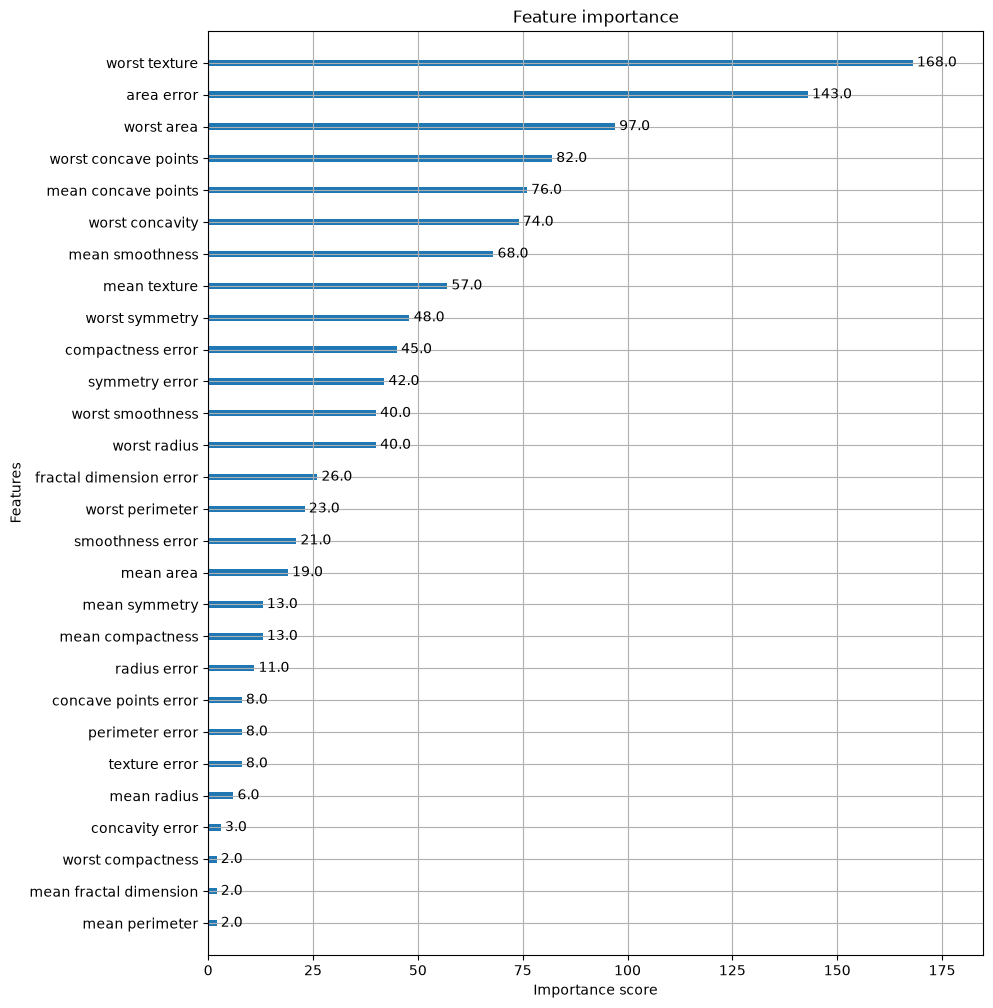

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_model, ax=ax)
plt.savefig('xgb_feature_importance.tif', format='tif', dpi=100)


### 사이킷런 래퍼 XGBoost의 적용

In [24]:
from xgboost import XGBClassifier

In [ ]:
# 훈련데이터와 훈련데이터의 정답을 넣어서 학습!!!
xgb_wrapper = XGBClassifier(
  n_estimators=400,
  learning_rate=0.1,
  max_depth=3
).fit(X_train, y_train)

# 예측!!
w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]
w_pred_proba

array([1.22467231e-04, 8.82567763e-01, 8.10745079e-03, 9.99901652e-01,
       9.98720527e-01, 9.98947322e-01, 1.23235285e-02, 5.20487629e-05,
       9.91718888e-01, 9.86708522e-01, 9.99857545e-01, 1.18135737e-04,
       5.57808889e-05, 2.50317971e-04, 9.99856591e-01, 1.55695617e-01,
       5.80357201e-03, 9.99422669e-01, 9.99312401e-01, 9.99082088e-01,
       3.74772966e-01, 9.99889016e-01, 1.64324674e-03, 4.54227586e-04,
       7.10980617e-04, 1.42863719e-04, 9.99718726e-01, 9.99561369e-01,
       9.99469101e-01, 9.99971032e-01, 9.83563423e-01, 8.99412096e-01,
       9.99864817e-01, 9.58506425e-05, 1.19600292e-04, 9.99609530e-01,
       9.99937773e-01, 9.99752223e-01, 9.99568641e-01, 2.06763449e-04,
       1.39042689e-03, 9.99695420e-01, 9.99363720e-01, 3.66398599e-04,
       9.99826133e-01, 1.45846163e-04, 9.94556785e-01, 9.97828186e-01,
       9.99913216e-01, 9.98003662e-01, 6.30762041e-01, 9.99822080e-01,
       9.98470366e-01, 3.41157895e-03, 9.75621939e-01, 9.74965036e-01,
      

In [38]:
get_clf_eval(y_test, w_preds, w_pred_proba)

오차 행렬
[[46  3]
 [ 1 64]]
정확도:0.9649122807017544, 정밀도:0.9552238805970149, 재현율:0.9846153846153847, f1-score:0.9696969696969697, AUC:0.9952904238618525


In [50]:
# 조기종료(early stopping)을 제공
evals = [(X_test, y_test)]

# 50번 반복동안 성능 개선이 없다면 조기 종료!! 
# early_stopping_rounds = 50
xgb_wrapper = XGBClassifier(n_estimators=400, learning_rate=0.1, max_depth=3, eval_metric='logloss', early_stopping_rounds = 50)

# 학습!! eval_set 학습에 사용할 검증용 데이터 제공
# verbose=False 참이면 처리내용이 안보이게 처리 
xgb_wrapper.fit(X_train, y_train, eval_set=evals, verbose=True)

w_preds = xgb_wrapper.predict(X_test)
w_pred_proba = xgb_wrapper.predict_proba(X_test)[:,1]

[0]	validation_0-logloss:0.61795


[1]	validation_0-logloss:0.54867
[2]	validation_0-logloss:0.49213
[3]	validation_0-logloss:0.44149
[4]	validation_0-logloss:0.40161
[5]	validation_0-logloss:0.36658
[6]	validation_0-logloss:0.33482
[7]	validation_0-logloss:0.30769
[8]	validation_0-logloss:0.28396
[9]	validation_0-logloss:0.26464
[10]	validation_0-logloss:0.24592
[11]	validation_0-logloss:0.22909
[12]	validation_0-logloss:0.21423
[13]	validation_0-logloss:0.20119
[14]	validation_0-logloss:0.19018
[15]	validation_0-logloss:0.18172
[16]	validation_0-logloss:0.17442
[17]	validation_0-logloss:0.16830
[18]	validation_0-logloss:0.16052
[19]	validation_0-logloss:0.15446
[20]	validation_0-logloss:0.15040
[21]	validation_0-logloss:0.14676
[22]	validation_0-logloss:0.14378
[23]	validation_0-logloss:0.13889
[24]	validation_0-logloss:0.13505
[25]	validation_0-logloss:0.13196
[26]	validation_0-logloss:0.13056
[27]	validation_0-logloss:0.12764
[28]	validation_0-logloss:0.12600
[29]	validation_0-logloss:0.12183
[30]	validation_0-loglo

In [51]:
get_clf_eval(y_test, w_preds, w_pred_proba)

print("최적 학습 라운드:", xgb_wrapper.best_iteration)
print("최적 LogLoss:", xgb_wrapper.best_score)

오차 행렬
[[47  2]
 [ 1 64]]
정확도:0.9736842105263158, 정밀도:0.9696969696969697, 재현율:0.9846153846153847, f1-score:0.9770992366412213, AUC:0.9952904238618525
최적 학습 라운드: 146
최적 LogLoss: 0.08618375495101199
